# Attempt-Level Model (Clean Features)
Pipeline: Load → Clean → Drop → Select → Train → Evaluate

In [31]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns
import matplotlib.pyplot as plt


## Load Data

In [32]:
df = pd.read_excel('Attempt Level Combined.xlsx')
print(df.shape)
print(df.columns.tolist())
df.head()

(180, 30)
['UserID', 'AttemptID', 'Handedness', 'TotalCompletionTime', 'ClickCount', 'TotalDrags', 'SuccessfulDrops', 'DragSuccessRate', 'TotalDistance', 'StraightLineDistance', 'TrajectoryLengthRatio', 'MovementEfficiency', 'AvgSpeed', 'MaxSpeed', 'SpeedStdDev', 'AvgAcceleration', 'MaxAcceleration', 'AccelerationStdDev', 'AvgJerk', 'MaxJerk', 'AvgAngleChange', 'TrajectoryCurvature', 'PauseCount', 'PauseTime', 'MovementCount', 'AvgDragDuration', 'MaxDragDuration', 'AvgDragDistance', 'AvgDragTrajectoryRatio', 'AvgDragCurvature']


,UserID,AttemptID,Handedness,TotalCompletionTime,ClickCount,TotalDrags,SuccessfulDrops,DragSuccessRate,TotalDistance,StraightLineDistance,...,AvgAngleChange,TrajectoryCurvature,PauseCount,PauseTime,MovementCount,AvgDragDuration,MaxDragDuration,AvgDragDistance,AvgDragTrajectoryRatio,AvgDragCurvature
0,A01,attempt_1,right,13.4644,0,6,6,1.0,6417.5010,665.1443,...,0.282347,0.022218,27,4.8865,507,0.7193,1.3016,537.3534,1.027620,0.012205
1,A01,attempt_2,right,11.9058,0,6,6,1.0,4741.7449,634.3311,...,0.283154,0.026454,24,4.2762,445,0.6991,0.9740,421.6006,1.021796,0.013446
2,A01,attempt_3,right,11.7223,0,6,6,1.0,6015.8326,640.2812,...,0.255923,0.018718,24,4.1527,442,0.7372,0.9895,512.5653,1.007471,0.008169
3,A01,attempt_4,right,10.9134,0,6,6,1.0,5120.0643,670.8577,...,0.273669,0.022075,22,3.7405,415,0.6813,0.8087,450.2654,1.008852,0.013900
4,A01,attempt_5,right,12.0098,1,6,6,1.0,5970.2642,528.2282,...,0.255372,0.018478,31,4.9222,434,0.6697,0.7827,462.8231,1.009829,0.009207


## Clean + Encode

In [33]:
df['Handedness'] = df['Handedness'].str.lower().str.strip()
df['HandednessEncoded'] = df['Handedness'].map({'left':0,'right':1})
df[['Handedness','HandednessEncoded']].head()

,Handedness,HandednessEncoded
0,right,1
1,right,1
2,right,1
3,right,1
4,right,1


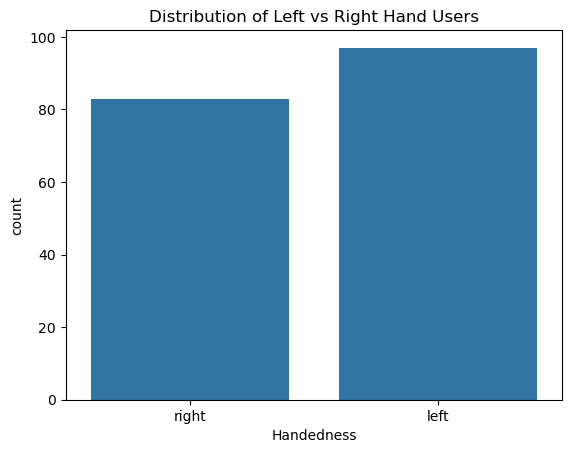

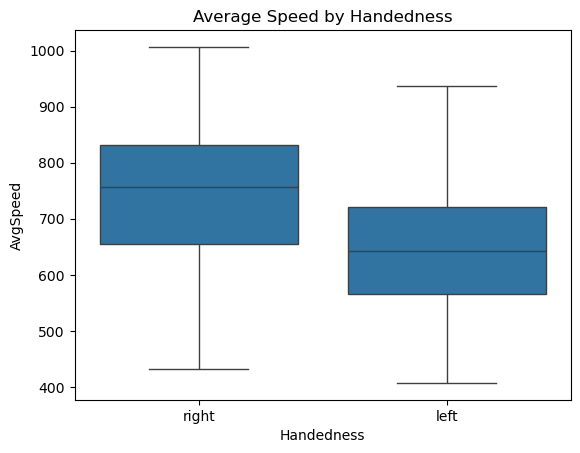

In [34]:
sns.countplot(x='Handedness', data=df)
plt.title("Distribution of Left vs Right Hand Users")
plt.show()

sns.boxplot(x='Handedness', y='AvgSpeed', data=df)
plt.title("Average Speed by Handedness")
plt.show()

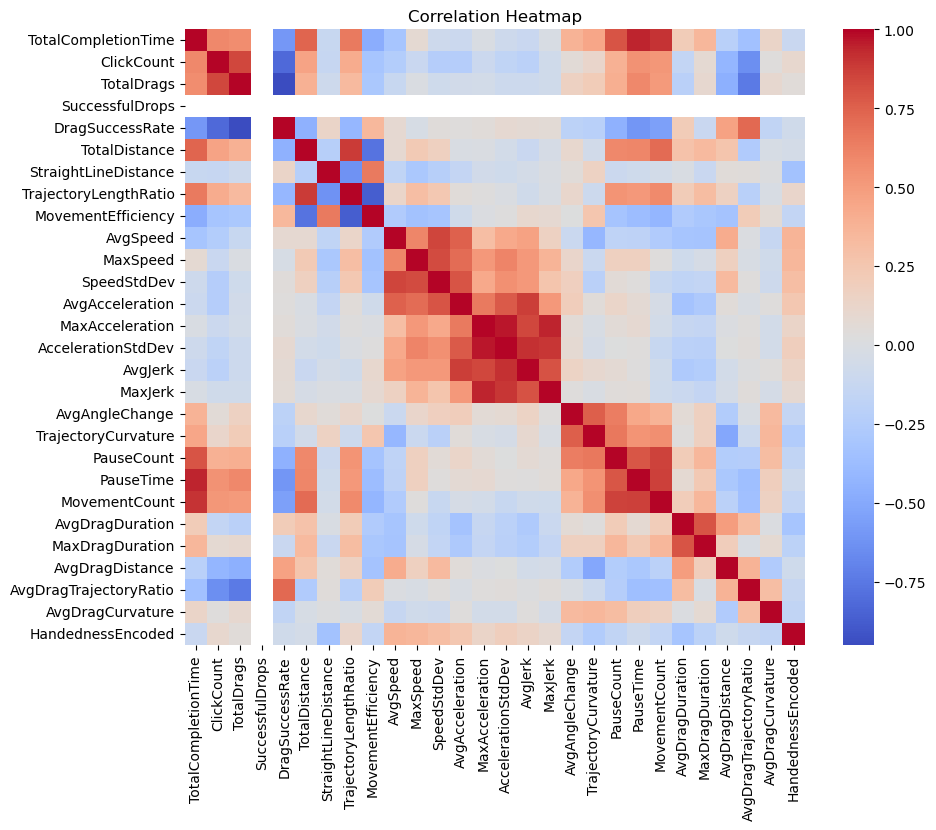

In [35]:
plt.figure(figsize=(10,8))

corr = df.corr(numeric_only=True)

sns.heatmap(corr, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

## Drop Weak / Redundant Features

In [36]:
drop_cols = [
    'AttemptID','UserID','StraightLineDistance','TrajectoryLengthRatio',
    'SpeedStdDev','AccelerationStdDev','MaxJerk','AvgJerk','MaxAcceleration',
    'MaxDragDuration','AvgDragDistance','AvgDragTrajectoryRatio','AvgDragCurvature',
    'SuccessfulDrops','MaxSpeed','TotalCompletionTime'
]
df = df.drop(columns=[c for c in drop_cols if c in df.columns])
print(df.columns)

Index(['Handedness', 'ClickCount', 'TotalDrags', 'DragSuccessRate',
       'TotalDistance', 'MovementEfficiency', 'AvgSpeed', 'AvgAcceleration',
       'AvgAngleChange', 'TrajectoryCurvature', 'PauseCount', 'PauseTime',
       'MovementCount', 'AvgDragDuration', 'HandednessEncoded'],
      dtype='object')


In [37]:
corr_target = corr['HandednessEncoded'].sort_values(ascending=False)
print(corr_target)

HandednessEncoded         1.000000
AvgSpeed                  0.369346
MaxSpeed                  0.352237
SpeedStdDev               0.307795
AvgAcceleration           0.248635
AccelerationStdDev        0.184305
AvgJerk                   0.144698
MaxAcceleration           0.135276
TrajectoryLengthRatio     0.118575
ClickCount                0.105226
MaxJerk                   0.085792
TotalDrags                0.050283
TotalDistance            -0.047531
DragSuccessRate          -0.069225
AvgDragDistance          -0.075839
PauseTime                -0.087031
TotalCompletionTime      -0.117711
AvgDragTrajectoryRatio   -0.135297
AvgAngleChange           -0.146514
MovementEfficiency       -0.156925
MovementCount            -0.159282
AvgDragCurvature         -0.162347
PauseCount               -0.166107
MaxDragDuration          -0.192571
TrajectoryCurvature      -0.255489
AvgDragDuration          -0.311880
StraightLineDistance     -0.341341
SuccessfulDrops                NaN
Name: HandednessEnco

## Feature Selection

In [38]:
features = [
    'TrajectoryCurvature',
    'AvgAngleChange',
    'MovementEfficiency',
    'MovementCount',
    'PauseCount',
    'TotalDistance'
]
X = df[features]
y = df['HandednessEncoded']

In [39]:
model = RandomForestClassifier(n_estimators=200, random_state=42)
model.fit(X, y)

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


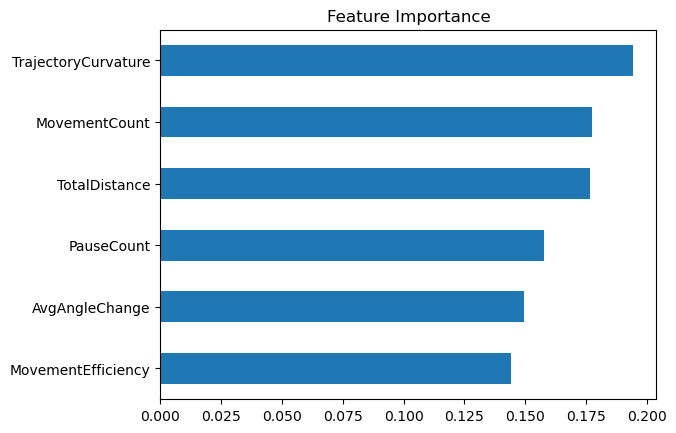

In [40]:
importances = pd.Series(model.feature_importances_, index=X.columns)

importances.sort_values().plot(kind='barh')
plt.title("Feature Importance")
plt.show()

## Train/Test Split

In [41]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print(len(X_train), len(X_test))

144 36


## Train Model

In [42]:
model = RandomForestClassifier(n_estimators=200, random_state=42)
model.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## Evaluate

In [43]:
y_pred = model.predict(X_test)
print('Accuracy:', accuracy_score(y_test,y_pred))
print(classification_report(y_test,y_pred))

Accuracy: 0.6666666666666666
              precision    recall  f1-score   support

           0       0.68      0.75      0.71        20
           1       0.64      0.56      0.60        16

    accuracy                           0.67        36
   macro avg       0.66      0.66      0.66        36
weighted avg       0.66      0.67      0.66        36



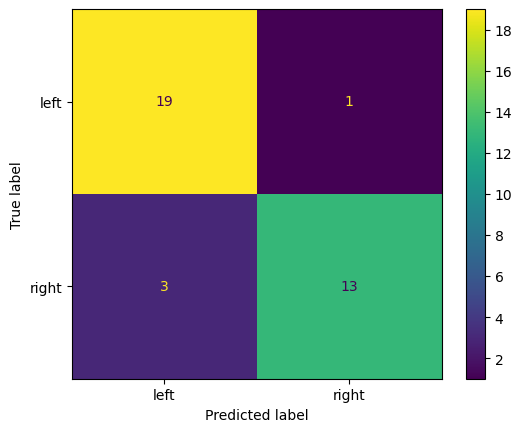

In [30]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['left', 'right'])
disp.plot()
plt.show()